# GSB 5544 — Topic 8.2: Regression in Python — SOLUTION
*You already know regression. This is how to run it in Python, and how it introduces machine learning.*

## The next 20 minutes

You have fit linear models before: assumptions, reading coefficients, polynomial terms, interactions.
None of that is re-taught here. Two things are new:

1. **How to do it in Python** with scikit-learn: one recipe that every model in this course will follow.
2. **Machine-learning vocabulary**, introduced on the familiar ground of a linear model: features and
   target, fit and predict, training and test data, overfitting.

| | | tools |
|---|---|---|
| **1. Data** | 200 markets, ad budgets and sales | `read_csv`, `corr`, `geom_smooth(method="lm")` |
| **2. The scikit-learn recipe** | fit a line, read it, predict with it | `LinearRegression`, `.fit`, `.coef_`, `.predict`, `.score` |
| **3. More terms** | more features, interactions, polynomials are all just more columns | `PolynomialFeatures` |
| **4. The machine-learning turn** | how well does the model predict data it has not seen? | `train_test_split`, `root_mean_squared_error`, `make_pipeline` |

In [1]:
import numpy as np
import pandas as pd
from plotnine import ggplot, aes, geom_point, geom_smooth, geom_line, labs, theme_minimal
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error

---
## 1. Data

**Question.** A product is advertised in 200 markets with different **TV**, **radio** and **newspaper**
budgets (in \$1,000s). Which budgets move **sales** (1,000s of units), and what sales should a new budget
produce?

One row per market. (The Advertising data from *An Introduction to Statistical Learning*; a copy is in the
course repo as `assignments/Data/advertising.csv`.)

In [2]:
ads = pd.read_csv("https://www.statlearning.com/s/Advertising.csv", index_col=0)
print(ads.shape)
ads.head()

(200, 4)


,TV,radio,newspaper,sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


The usual quick look: correlations, and the outcome against the strongest feature with a least-squares
line (`method="lm"`).

In [3]:
ads.corr().round(2)

,TV,radio,newspaper,sales
TV,1.00,0.05,0.06,0.78
radio,0.05,1.00,0.35,0.58
newspaper,0.06,0.35,1.00,0.23
sales,0.78,0.58,0.23,1.00


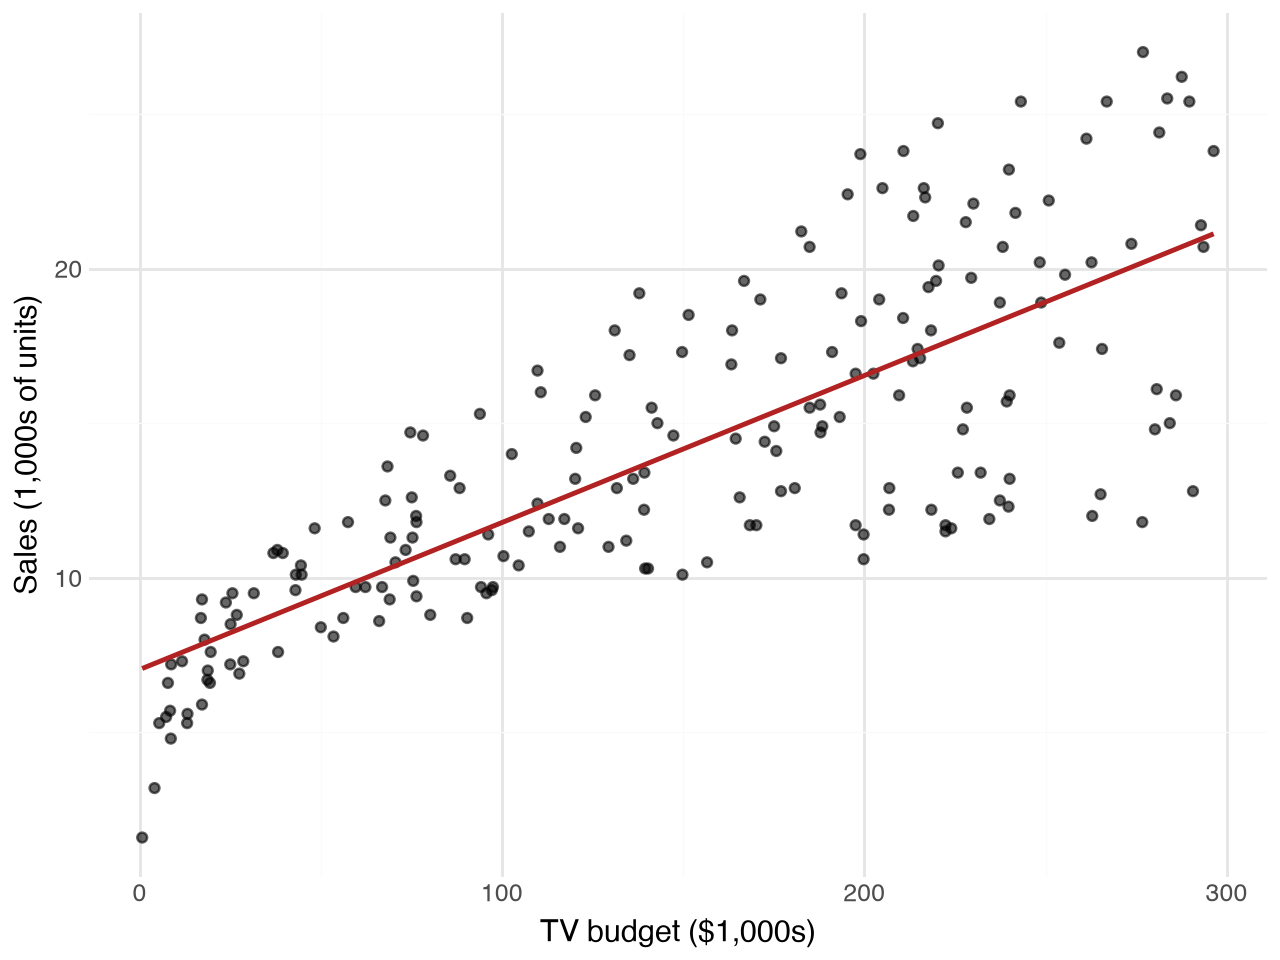

In [4]:
(ggplot(ads, aes(x="TV", y="sales"))
 + geom_point(alpha=0.6)
 + geom_smooth(method="lm", se=False, color="firebrick")
 + labs(x="TV budget ($1,000s)", y="Sales (1,000s of units)")
 + theme_minimal())

---
## 2. The scikit-learn recipe

Every scikit-learn model works the same way. Learn it once:

| step | code | |
|---|---|---|
| choose | `model = LinearRegression()` | an empty model |
| fit | `model.fit(X, y)` | learn the coefficients from data |
| read | `model.intercept_`, `model.coef_` | the trailing `_` means "learned from data" |
| use | `model.predict(X_new)`, `model.score(X, y)` | predictions; $R^2$ |

**Vocabulary.** `X` is the table of **features** (explanatory variables), `y` is the **target** (response).
`X` must be **2-D** — a DataFrame, even with one column — because features are always a table with one
column per feature. `y` is a Series.

In [5]:
X = ads[["TV"]]          # double brackets -> DataFrame (2-D)
y = ads["sales"]         # single brackets -> Series (1-D)
print(type(X).__name__, X.shape, "|", type(y).__name__, y.shape)

DataFrame (200, 1) | Series (200,)


In [6]:
model_tv = LinearRegression()
model_tv.fit(X, y)
print("intercept:", round(model_tv.intercept_, 4))
print("coef:     ", model_tv.coef_.round(4))
print("R²:       ", round(model_tv.score(X, y), 3))

intercept: 7.0326
coef:      [0.0475]
R²:        0.612


The error everyone hits once — single brackets give a 1-D Series. The key words in the message are
*2-dimensional* and *DataFrame*.

In [7]:
LinearRegression().fit(ads["TV"], ads["sales"])     # 1-D -> error

ValueError: Expected a 2-dimensional container but got <class 'pandas.Series'> instead. Pass a DataFrame containing a single row (i.e. single sample) or a single column (i.e. single feature) instead.

**Predict** takes a DataFrame with the **same column names** as `X`, one row per new case.

In [8]:
new = pd.DataFrame({"TV": [0, 100, 200, 300]})
new["pred_sales"] = model_tv.predict(new[["TV"]])
new

,TV,pred_sales
0,0,7.032594
1,100,11.786258
2,200,16.539922
3,300,21.293586


✅ **Checkpoint 1.** (a) Write the fitted equation and check the prediction at TV = 100 by hand.
(b) In one sentence, read the TV coefficient in the data's units.

**Answer:** (a) sales ≈ 7.03 + 0.0475 · TV; at TV = 100: 7.03 + 4.75 = **11.79** thousand units (matches the table).
(b) Each extra \$1,000 of TV budget is associated with about 47.5 more units sold.

---
## 3. More terms are just more columns

A second feature, an interaction, a squared term: in scikit-learn these are all the same move — **put
another column in `X`**. Nothing else in the recipe changes.

In [9]:
X2 = ads[["TV", "radio"]]
model_2 = LinearRegression().fit(X2, y)
print(pd.Series(model_2.coef_, index=X2.columns).round(4))
print("R²:", round(model_2.score(X2, y), 3))

TV       0.0458
radio    0.1880
dtype: float64
R²: 0.897


An **interaction** is a column you make yourself:

In [10]:
ads["TV_x_radio"] = ads["TV"] * ads["radio"]
X3 = ads[["TV", "radio", "TV_x_radio"]]
model_3 = LinearRegression().fit(X3, y)
print(pd.Series(model_3.coef_, index=X3.columns).round(5))
print("R²:", round(model_3.score(X3, y), 3))

TV            0.01910
radio         0.02886
TV_x_radio    0.00109
dtype: float64
R²: 0.968


**Polynomial terms** can be made the same way (`ads["TV"] ** 2`), or generated: `PolynomialFeatures(degree=2)`
builds every term up to that degree — squares *and* cross-products — from the columns you give it.
`fit_transform` returns a NumPy array; `get_feature_names_out()` tells you which column is which.

In [11]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(ads[["TV", "radio"]])
print(X_poly.shape)
print(poly.get_feature_names_out())

(200, 5)
['TV' 'radio' 'TV^2' 'TV radio' 'radio^2']


In [12]:
model_poly = LinearRegression().fit(X_poly, y)
print(pd.Series(model_poly.coef_, index=poly.get_feature_names_out()).round(5))
print("R²:", round(model_poly.score(X_poly, y), 3))

TV          0.05099
radio       0.02654
TV^2       -0.00011
TV radio    0.00107
radio^2     0.00019
dtype: float64
R²: 0.986


✅ **Checkpoint 2.** $R^2$ went 0.61 → 0.90 → 0.97 → 0.99 as terms were added. Can $R^2$ on the fitted data
ever go *down* when you add a column? What does that imply about using it to choose between models?

**Answer:** No — a new column can be given a coefficient of zero, so the fit can only stay the same or improve. Fitted
$R^2$ therefore always favours the bigger model and cannot tell you when you have gone too far. That is the
problem section 4 solves.

---
## 4. The machine-learning turn

Up to now the model was judged on the **same rows it was fitted on**. Machine learning asks a different
question: *how well does the model predict rows it has never seen?* The vocabulary:

| statistics says | machine learning says |
|---|---|
| explanatory variables, response | **features** `X`, **target** `y` |
| estimate the coefficients | **fit** / **train** the model |
| coefficients | **parameters** (learned by `.fit`) |
| model specification (which terms, which degree) | **hyperparameters** (chosen by *you*, before fitting) |
| goodness of fit | **training error** vs **test error** |

### Train / test split

Hold some rows back. Fit on the **training** rows; measure error on the **test** rows the model never saw.
`random_state` fixes the shuffle so everyone gets the same split.

In [13]:
train, test = train_test_split(ads, test_size=0.25, random_state=5544)
print(train.shape, test.shape)

(150, 5) (50, 5)


The error measure is **RMSE** (root mean squared error): the typical size of a miss, in the units of `y`.

In [14]:
features = ["TV", "radio"]
model = LinearRegression().fit(train[features], train["sales"])

rmse_train = root_mean_squared_error(train["sales"], model.predict(train[features]))
rmse_test = root_mean_squared_error(test["sales"], model.predict(test[features]))
print(f"train RMSE = {rmse_train:.3f}   test RMSE = {rmse_test:.3f}   (thousand units)")

train RMSE = 1.694   test RMSE = 1.617   (thousand units)


### Overfitting: turn the degree up and watch both errors

`make_pipeline` chains steps into one model object that still has `.fit` and `.predict`: scale the
features (polynomials of raw budgets in the hundreds are numerically unstable), build the polynomial
terms, fit the line. The **degree is a hyperparameter**: we loop over it and record training and test
RMSE for each.

In [15]:
rows = []
for degree in range(1, 11):
    pipe = make_pipeline(StandardScaler(), PolynomialFeatures(degree=degree), LinearRegression())
    pipe.fit(train[features], train["sales"])
    rows.append({"degree": degree,
                 "n_terms": pipe[-1].coef_.size,
                 "train": root_mean_squared_error(train["sales"], pipe.predict(train[features])),
                 "test": root_mean_squared_error(test["sales"], pipe.predict(test[features]))})
errors = pd.DataFrame(rows)
errors.round(3)

,degree,n_terms,train,test
0,1,3,1.694,1.617
1,2,6,0.659,0.460
2,3,10,0.525,0.371
3,4,15,0.451,0.383
4,5,21,0.392,0.400
5,6,28,0.314,0.465
6,7,36,0.283,0.455
7,8,45,0.259,0.431
8,9,55,0.248,0.538
9,10,66,0.241,0.710


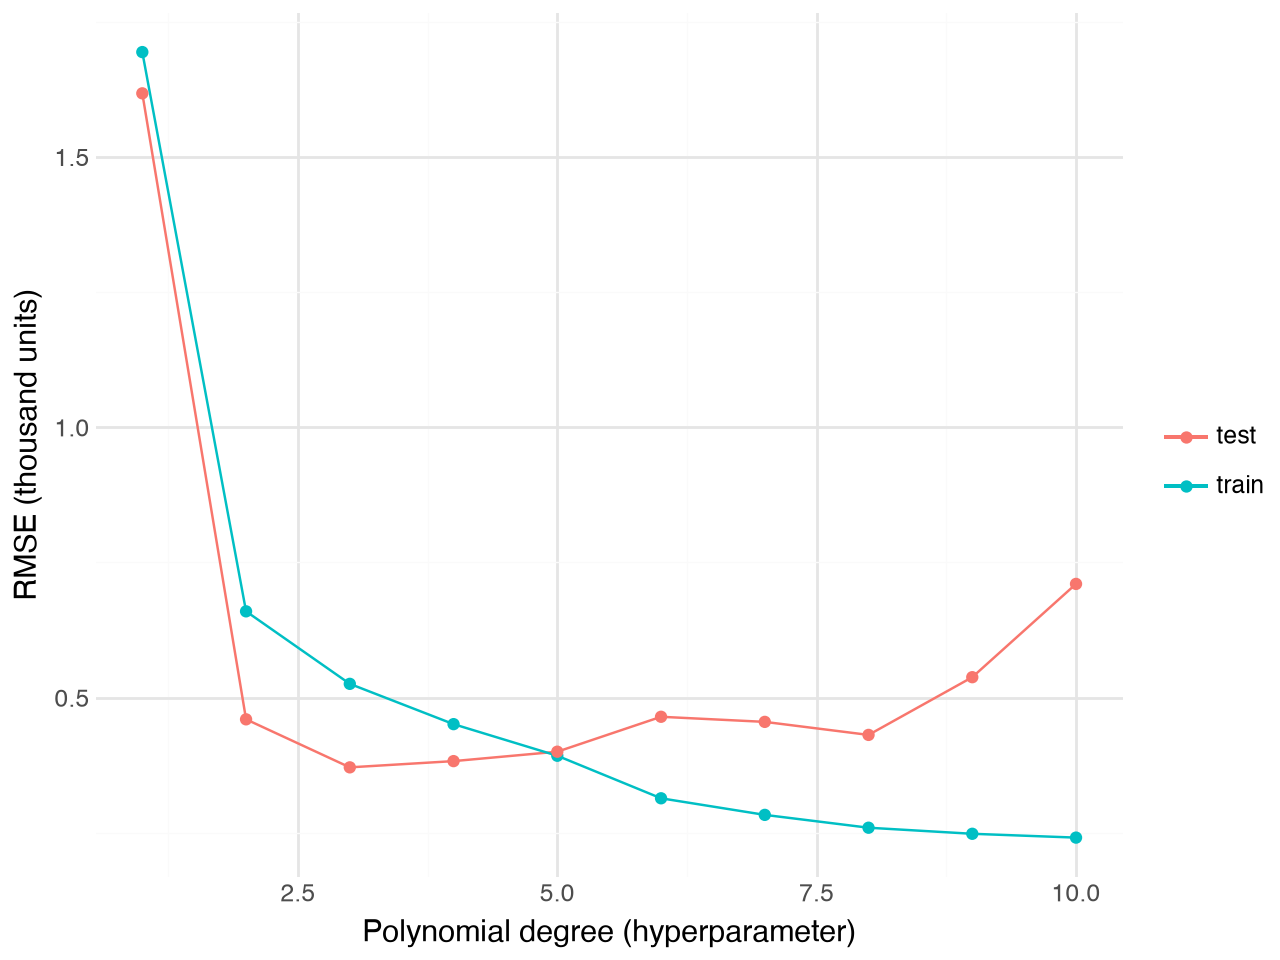

In [16]:
errors_long = errors.melt(id_vars="degree", value_vars=["train", "test"], var_name="data", value_name="rmse")
(ggplot(errors_long, aes(x="degree", y="rmse", color="data"))
 + geom_line() + geom_point()
 + labs(x="Polynomial degree (hyperparameter)", y="RMSE (thousand units)", color="")
 + theme_minimal())

✅ **Checkpoint 3.** (a) Describe the two curves. (b) Which degree would you choose, and why is that not
the degree with the lowest *training* error? (c) Name the phenomenon on the right-hand side of the plot.

**Answer:** (a) Training RMSE falls at every step (0.25 by degree 10): more terms always fit the fitted rows better.
Test RMSE drops sharply from degree 1 to 2, bottoms out around **degree 3** (≈ 0.37), then climbs back to
≈ 0.71 by degree 10. (b) Degree 2 or 3 — the lowest **test** error, with the simpler model preferred when
they are close. Training error keeps rewarding complexity, so it cannot be used to choose; that was
Checkpoint 2. (c) **Overfitting**: past degree 3 the model is fitting the noise in the 150 training rows
(66 terms for 150 rows by degree 10), and that does not carry over to new markets.

*One test split is one random draw.* The standard fix is **cross-validation** — several splits, averaged —
which is where the next topic starts.

---
## The lines to keep

| | |
|---|---|
| **Recipe** | `model = LinearRegression().fit(X, y)` → `model.intercept_`, `model.coef_` → `model.predict(new_df)`, `model.score(X, y)` |
| **`X` is a DataFrame** | double brackets, even for one feature; `predict` needs the same column names |
| **More terms** | more columns in `X`: a second feature, `ads["a"] * ads["b"]`, or `PolynomialFeatures(degree=d)` |
| **Train / test** | `train_test_split(df, test_size=0.25, random_state=…)`; fit on train, measure on test |
| **Choose a hyperparameter** | loop over it, compare **test** error; the fitted-data error only ever goes down |
| **Pipeline** | `make_pipeline(StandardScaler(), PolynomialFeatures(d), LinearRegression())` is one model with `.fit` / `.predict` |

Course site: [https://gato365.github.io/gsb5544_instructor_learn_prep/](https://gato365.github.io/gsb5544_instructor_learn_prep/).